# CitizenTech — Rede neural para monitoramento ambiental urbano
## Global Solution 2026.2 | Redes Neurais Artificiais, Deep Learning e Algoritmos Genéticos

**Integrantes:**

- João Pedro Morangoni — RM 570073
- João Vitor Xavier de Carvalho — RM 570633

**Entrega:** estimativa de monóxido de carbono (CO) com uma rede MLP, usando exclusivamente
`IA/dataset/AirQualityUCI.csv`. O notebook cobre as oito etapas do enunciado:
problema, dataset, preparação, arquitetura, treinamento, refinamento, avaliação e demonstração.
As células Markdown explicam as decisões; as saídas registram a execução real.

## 1. Problema, público e aplicação

O projeto do repositório monitora bueiros para apoiar a manutenção urbana. Este experimento
propõe um **módulo complementar de qualidade do ar em superfície**, voltado a equipes
municipais de manutenção, gestores e moradores próximos às vias monitoradas. A RNA estima
a concentração média horária de CO com sensores químicos e variáveis meteorológicas.
Isso pode apoiar um painel ambiental territorial junto ao monitoramento de infraestrutura.

**Entradas:** cinco respostas de sensores PT08, temperatura, umidade relativa e absoluta.
**Saída:** um número contínuo, CO em mg/m³, no mesmo horário das entradas.
É regressão e calibração indireta de sensores, não previsão de uma hora futura.

O Air Quality não contém nível de água, obstrução, chuva nem gases medidos dentro de
bueiros. Portanto, este modelo não estima alagamento e não valida segurança de entrada
em espaço confinado. A compatibilidade desse módulo complementar com o escopo do grupo
precisa ser confirmada na entrega interdisciplinar. O firmware atual usa sensores diferentes;
a integração completa é uma evolução, demonstrada aqui por simulação funcional.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import platform
import sys
import importlib.metadata as metadata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
# Executável a partir da raiz do repositório, de IA ou de rede_neural.
RAIZ_IA = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "dataset" / "AirQualityUCI.csv").is_file()), None)
if RAIZ_IA is None and (Path.cwd() / "IA/dataset/AirQualityUCI.csv").is_file():
    RAIZ_IA = Path.cwd() / "IA"
if RAIZ_IA is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório GS-CitizenTech.")
CSV = RAIZ_IA / "dataset/AirQualityUCI.csv"
SAIDA = RAIZ_IA / "rede_neural/artefatos"
DOC = RAIZ_IA / "documentacao"
SAIDA.mkdir(parents=True, exist_ok=True)
(DOC / "figuras").mkdir(parents=True, exist_ok=True)
VERSOES = {p: metadata.version(p) for p in
           ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient", "ipykernel"]}
print("Python:", platform.python_version())
display(pd.Series(VERSOES, name="Versão executada").to_frame())
print("Dataset:", CSV.name, "| SHA-256:", hashlib.sha256(CSV.read_bytes()).hexdigest())

Python: 3.15.2


,Versão executada
numpy,2.5.5
pandas,3.1.1
scikit-learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


Dataset: AirQualityUCI.csv | SHA-256: 13277ae5d8581e80b7be09d47c7d3d06fe9b8e957078f2cf6e859f955e62f996


## 2. Fonte e compreensão dos dados

Fonte: [UCI Machine Learning Repository — Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality).
Referência: Vito, S. (2008). *Air Quality* [Dataset]. DOI: [10.24432/C59K5F](https://doi.org/10.24432/C59K5F).
A base registra médias horárias de um dispositivo multissensor em uma cidade italiana,
com concentrações de referência de um analisador certificado. Há sensibilidades cruzadas
e deriva dos sensores, tornando a calibração multivariada uma tarefa pertinente à MLP.

O valor `-200` indica ausência. O CSV usa `;` e vírgula decimal e inclui colunas e linhas
vazias. As contagens e o período abaixo são calculados no arquivo local; o resumo da UCI
e o conteúdo do CSV podem divergir em uma observação ou no período descrito.
O portal apresenta licença CC BY 4.0 e também uma observação de uso para pesquisa;
este trabalho limita-se ao uso acadêmico e preserva a atribuição.

Arquivo: (9471, 17); registros datados: 9357
Período local: 2004-03-10 18:00:00 a 2005-04-04 14:00:00


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,instante
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,7674.000,8991.000,914.000,8991.000,8991.000,7718.000,8991.000,7715.000,8991.000,8991.000,8991.000,8991.000,8991.000
mean,2.153,1099.833,218.812,10.083,939.153,246.897,835.494,113.091,1456.265,1022.906,18.318,49.234,1.026
std,1.453,217.080,204.460,7.450,266.831,212.979,256.817,48.370,346.207,398.484,8.832,17.317,0.404
min,0.100,647.000,7.000,0.100,383.000,2.000,322.000,2.000,551.000,221.000,-1.900,9.200,0.185
25%,1.100,937.000,67.000,4.400,734.500,98.000,658.000,78.000,1227.000,731.500,11.800,35.800,0.737
50%,1.800,1063.000,150.000,8.200,909.000,180.000,806.000,109.000,1463.000,963.000,17.800,49.600,0.995
75%,2.900,1231.000,297.000,14.000,1116.000,326.000,969.500,142.000,1674.000,1273.500,24.400,62.500,1.314
max,11.900,2040.000,1189.000,63.700,2214.000,1479.000,2683.000,340.000,2775.000,2523.000,44.600,88.700,2.231


,Ausentes (-200 ou NaN)
NMHC(GT),8443
CO(GT),1683
NO2(GT),1642
NOx(GT),1639
PT08.S1(CO),366
PT08.S2(NMHC),366
C6H6(GT),366
PT08.S3(NOx),366
PT08.S4(NO2),366
PT08.S5(O3),366


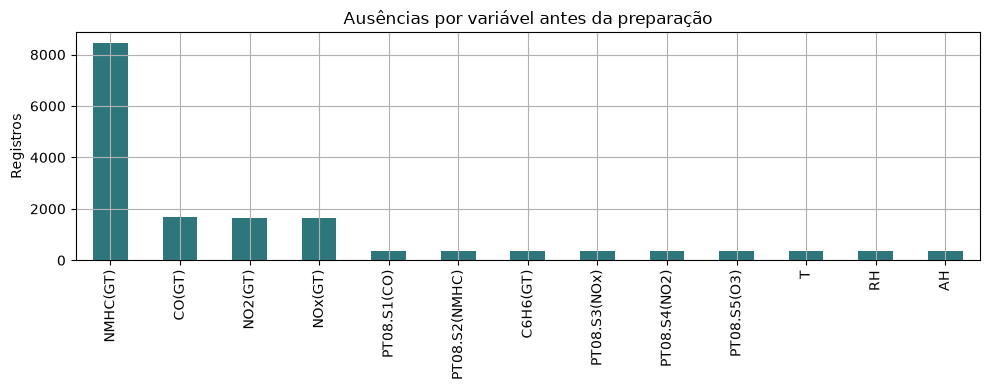

In [2]:
bruto = pd.read_csv(CSV, sep=";", decimal=",")
dados = bruto.dropna(axis=1, how="all").dropna(axis=0, how="all").copy()
numericas = dados.select_dtypes(include="number").columns
ausencias = dados[numericas].replace(-200, np.nan).isna().sum().sort_values(ascending=False)
dados[numericas] = dados[numericas].replace(-200, np.nan)
dados["instante"] = pd.to_datetime(dados["Date"] + " " + dados["Time"],
                                     format="%d/%m/%Y %H.%M.%S", errors="coerce")
assert dados["instante"].notna().all(), "Investigue datas inválidas antes de prosseguir."
assert not dados["instante"].duplicated().any(), "Investigue horários duplicados."
dados = dados.sort_values("instante").reset_index(drop=True)
print(f"Arquivo: {bruto.shape}; registros datados: {len(dados)}")
print("Período local:", dados.instante.min(), "a", dados.instante.max())
display(dados.head())
display(dados[numericas].describe().round(3))
display(ausencias.rename("Ausentes (-200 ou NaN)").to_frame())
fig, ax = plt.subplots()
ausencias.plot.bar(ax=ax, color="#2d777c")
ax.set(title="Ausências por variável antes da preparação", ylabel="Registros")
fig.tight_layout(); fig.savefig(DOC / "figuras/ausencias.png", dpi=140)
plt.show()

## 3. Preparação e divisão cronológica

Usamos apenas as oito medições disponíveis em um dispositivo ambiental: cinco sensores
e três variáveis meteorológicas. Os demais campos `GT` são concentrações de laboratório;
não entram no modelo, pois sua disponibilidade em produção invalidaria a proposta de
estimar CO a partir de sensores. Datas servem para ordenar e auditar a avaliação.

Removemos linhas sem CO de referência, sem imputar o alvo, e linhas com todas as entradas
ausentes. Mantemos entradas parcialmente ausentes, imputadas pela mediana **do treino**,
com indicadores de ausência. Não interpolamos usando medições futuras.
Separamos aproximadamente 60% / 20% / 20% na ordem temporal: treino, validação e teste.
Isso evita a mistura aleatória de horas próximas. O teste permanece reservado até
concluir a escolha do modelo. A normalização de entradas e alvo também usa só o treino.

In [3]:
FEATURES = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)",
            "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"]
ALVO = "CO(GT)"
sem_alvo = dados[ALVO].isna()
sem_entradas = dados[FEATURES].isna().all(axis=1)
base = dados.loc[~sem_alvo & ~sem_entradas].copy().reset_index(drop=True)
assert (base[ALVO] >= 0).all()
n = len(base); corte1, corte2 = int(n * .6), int(n * .8)
treino, validacao, teste = base.iloc[:corte1], base.iloc[corte1:corte2], base.iloc[corte2:]
assert treino.instante.max() < validacao.instante.min() < teste.instante.min()
assert not treino[FEATURES].isna().all().any()
resumo_divisao = pd.DataFrame([
    {"conjunto": nome, "amostras": len(df), "inicio": str(df.instante.min()),
     "fim": str(df.instante.max()), "CO_medio": df[ALVO].mean()}
    for nome, df in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]])
print("Sem alvo:", int(sem_alvo.sum()), "| Sem entradas:", int(sem_entradas.sum()),
      "| Removidos (união):", len(dados) - len(base), "| Utilizados:", n)
display(resumo_divisao)
preprocessador = Pipeline([
    ("imputacao", SimpleImputer(strategy="median", add_indicator=True)),
    ("padronizacao", StandardScaler()),
])
Xtr = preprocessador.fit_transform(treino[FEATURES])
Xva = preprocessador.transform(validacao[FEATURES])
ytr = treino[ALVO].to_numpy(); yva = validacao[ALVO].to_numpy()
escala_alvo = StandardScaler().fit(ytr.reshape(-1, 1))
ytr_z = escala_alvo.transform(ytr.reshape(-1, 1)).ravel()
assert np.isfinite(Xtr).all() and np.isfinite(Xva).all()
print("Entradas originais:", len(FEATURES), "| Entradas após indicadores:", Xtr.shape[1])

Sem alvo: 1683 | Sem entradas: 366 | Removidos (união): 2013 | Utilizados: 7344


,conjunto,amostras,inicio,fim,CO_medio
0,Treino,4406,2004-03-10 18:00:00,2004-11-15 10:00:00,2.050113
1,Validação,1469,2004-11-15 11:00:00,2005-01-28 11:00:00,2.548468
2,Teste,1469,2005-01-28 12:00:00,2005-04-04 14:00:00,1.949694


Entradas originais: 8 | Entradas após indicadores: 8


## 4. Arquitetura e funcionamento

Uma **MLP (perceptron multicamadas)** é adequada a estas entradas tabulares numéricas.
Não há imagens que justifiquem CNN. Uma RNN exigiria janelas e outro desenho temporal;
a tarefa atual estima CO da mesma hora, sem modelar sequências explicitamente.

Fluxo: 8 medições → imputação + indicadores → padronização → camada(s) densa(s)
com ReLU → 1 neurônio com saída linear → inversão da escala do alvo → CO em mg/m³.
Cada neurônio calcula uma soma ponderada mais viés, seguida de ativação; o Adam ajusta
pesos por retropropagação para reduzir erro quadrático. Aplicamos `max(0, saída)` após
restaurar a unidade física, tanto na seleção quanto na avaliação e na inferência.

A implementação utiliza `MLPRegressor` do scikit-learn: é uma RNA treinada por
retropropagação, sem necessidade de TensorFlow. A dimensão real da entrada inclui
os indicadores de ausência aprendidos no treino e será registrada com o total de parâmetros.

## 5–6. Treinamento, refinamento e regularização

Comparamos quatro configurações predefinidas, alterando profundidade, neurônios,
learning rate, batch size e penalidade L2 (`alpha`). O critério é o menor RMSE de
validação, nunca o erro no teste. O modelo inicial tem uma camada com 16 neurônios.

Cada `partial_fit` percorre uma época e preserva o estado do Adam. O treinamento tem
limite de 250 épocas, paciência de 25 épocas e melhora mínima de 0,001 mg/m³ para
reiniciar a paciência. Guardamos uma cópia dos pesos de menor RMSE de validação.
O early stopping é manual para usar o bloco cronológico de validação; a opção interna
do scikit-learn criaria uma divisão aleatória. L2 e early stopping reduzem o risco de
overfitting. Não usamos dropout, indisponível nesta implementação e não obrigatório.

O embaralhamento ocorre somente dentro do treino a cada época. As fronteiras temporais
não mudam. Os checkpoints finais continuam treinados somente no primeiro bloco;
não fazemos um novo ajuste juntando treino e validação após a seleção.

In [4]:
MAX_EPOCAS, PACIENCIA, MIN_DELTA = 250, 25, 0.001
CONFIGS = [
    dict(nome="Inicial_16", camadas=(16,), lr=0.001, batch=128, alpha=0.0001),
    dict(nome="MLP_32_16_L2", camadas=(32, 16), lr=0.001, batch=128, alpha=0.01),
    dict(nome="MLP_64_32_L2", camadas=(64, 32), lr=0.0005, batch=256, alpha=0.01),
    dict(nome="MLP_32_16_L2_forte", camadas=(32, 16), lr=0.0005, batch=256, alpha=0.1),
]

def predizer(rede, X):
    return np.maximum(0, escala_alvo.inverse_transform(rede.predict(X).reshape(-1, 1)).ravel())

def metricas(y, p):
    return {"MAE": float(mean_absolute_error(y, p)),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": float(r2_score(y, p))}

historicos, modelos, linhas = {}, {}, []
with threadpool_limits(limits=1):
    for cfg in CONFIGS:
        rede = MLPRegressor(hidden_layer_sizes=cfg["camadas"], activation="relu",
                            solver="adam", alpha=cfg["alpha"], batch_size=cfg["batch"],
                            learning_rate_init=cfg["lr"], max_iter=1, shuffle=True,
                            early_stopping=False, random_state=SEED)
        melhor_rmse, referencia, espera = np.inf, np.inf, 0
        historico, melhor_rede, melhor_epoca = [], None, 0
        for epoca in range(1, MAX_EPOCAS + 1):
            rede.partial_fit(Xtr, ytr_z)
            mtr = metricas(ytr, predizer(rede, Xtr))
            mva = metricas(yva, predizer(rede, Xva))
            historico.append(dict(epoca=epoca, loss=float(rede.loss_),
                                  rmse_treino=mtr["RMSE"], rmse_validacao=mva["RMSE"]))
            if mva["RMSE"] < melhor_rmse:
                melhor_rmse, melhor_epoca = mva["RMSE"], epoca
                melhor_rede = copy.deepcopy(rede)
            if mva["RMSE"] < referencia - MIN_DELTA:
                referencia, espera = mva["RMSE"], 0
            else:
                espera += 1
            if espera >= PACIENCIA:
                break
        modelos[cfg["nome"]] = melhor_rede
        historicos[cfg["nome"]] = pd.DataFrame(historico)
        linhas.append({**cfg, "epocas_executadas": epoca, "melhor_epoca": melhor_epoca,
                       **metricas(yva, predizer(melhor_rede, Xva)),
                       "RMSE_treino": metricas(ytr, predizer(melhor_rede, Xtr))["RMSE"]})
comparacao = pd.DataFrame(linhas).sort_values("RMSE").reset_index(drop=True)
NOME_MELHOR = comparacao.iloc[0]["nome"]
melhor = modelos[NOME_MELHOR]
print("Selecionado exclusivamente na validação:", NOME_MELHOR)
display(comparacao)
dimensoes = [Xtr.shape[1], *melhor.hidden_layer_sizes, 1]
parametros = sum(w.size + b.size for w, b in zip(melhor.coefs_, melhor.intercepts_))
print("Arquitetura selecionada:", " → ".join(map(str, dimensoes)))
print("Parâmetros treináveis:", parametros)
comparacao.to_csv(SAIDA / "comparacao_validacao.csv", index=False)

Selecionado exclusivamente na validação: Inicial_16


,nome,camadas,lr,batch,alpha,epocas_executadas,melhor_epoca,MAE,RMSE,R2,RMSE_treino
0,Inicial_16,"(16,)",0.0010,128,0.0001,210,210,0.458724,0.730687,0.818368,0.276477
1,MLP_64_32_L2,"(64, 32)",0.0005,256,0.0100,71,49,0.458385,0.730762,0.818330,0.273670
2,MLP_32_16_L2_forte,"(32, 16)",0.0005,256,0.1000,250,249,0.463692,0.739836,0.813791,0.271001
3,MLP_32_16_L2,"(32, 16)",0.0010,128,0.0100,65,64,0.474666,0.744049,0.811664,0.274611


Arquitetura selecionada: 8 → 16 → 1
Parâmetros treináveis: 161


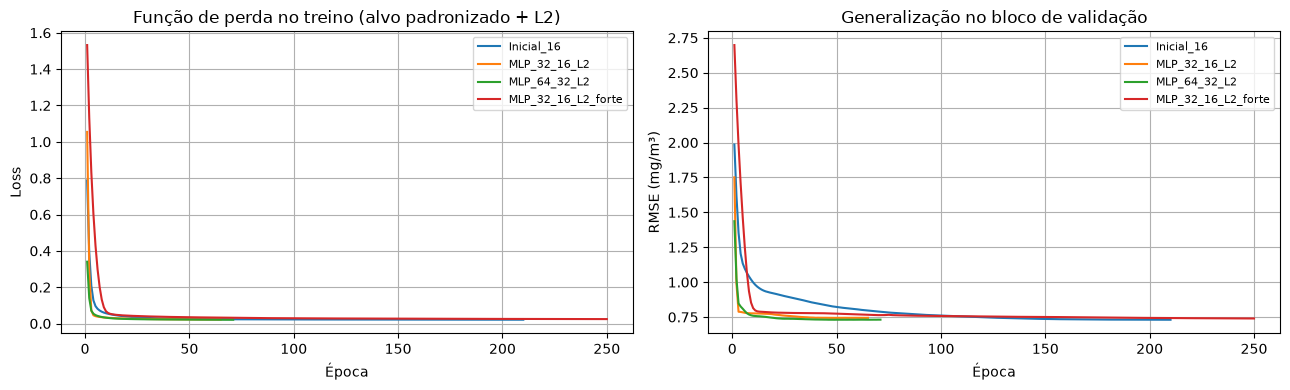

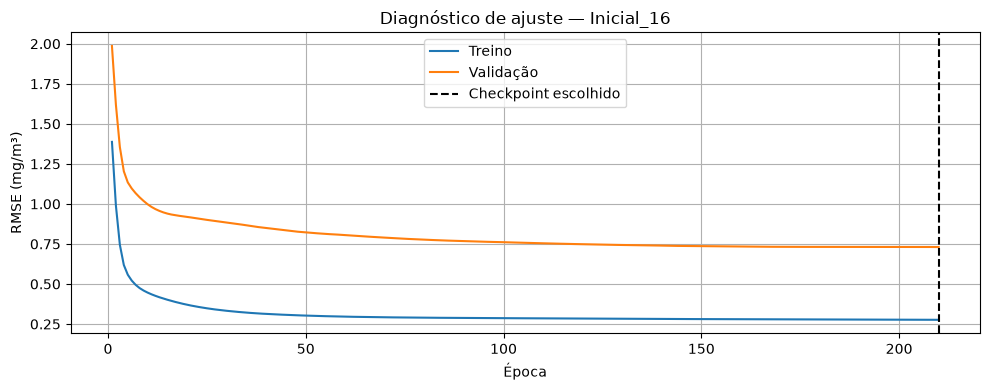

A configuração selecionada reduziu o RMSE de validação em **0.0%** em relação à inicial. RMSE treino: **0.276**; validação: **0.731 mg/m³**. Uma diferença entre os blocos pode refletir sobreajuste e também deriva temporal; essas causas não podem ser isoladas apenas por esta curva. Se a inicial vencer, o refinamento não trouxe ganho e preservamos a configuração inicial.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for nome, h in historicos.items():
    axes[0].plot(h.epoca, h.loss, label=nome)
    axes[1].plot(h.epoca, h.rmse_validacao, label=nome)
    h.to_csv(SAIDA / f"historico_{nome}.csv", index=False)
axes[0].set(title="Função de perda no treino (alvo padronizado + L2)", xlabel="Época", ylabel="Loss")
axes[1].set(title="Generalização no bloco de validação", xlabel="Época", ylabel="RMSE (mg/m³)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(DOC / "figuras/treinamento.png", dpi=140); plt.show()
h = historicos[NOME_MELHOR]
fig, ax = plt.subplots()
ax.plot(h.epoca, h.rmse_treino, label="Treino")
ax.plot(h.epoca, h.rmse_validacao, label="Validação")
ax.axvline(int(comparacao.iloc[0].melhor_epoca), color="black", linestyle="--", label="Checkpoint escolhido")
ax.set(title=f"Diagnóstico de ajuste — {NOME_MELHOR}", xlabel="Época", ylabel="RMSE (mg/m³)")
ax.legend(); fig.tight_layout(); fig.savefig(DOC / "figuras/ajuste.png", dpi=140); plt.show()
inicial = comparacao.loc[comparacao.nome == "Inicial_16"].iloc[0]
ganho_val = 100 * (inicial.RMSE - comparacao.iloc[0].RMSE) / inicial.RMSE
display(Markdown(f"A configuração selecionada reduziu o RMSE de validação em **{ganho_val:.1f}%** "
                 f"em relação à inicial. RMSE treino: **{comparacao.iloc[0].RMSE_treino:.3f}**; "
                 f"validação: **{comparacao.iloc[0].RMSE:.3f} mg/m³**. "
                 "Uma diferença entre os blocos pode refletir sobreajuste e também deriva temporal; "
                 "essas causas não podem ser isoladas apenas por esta curva. Se a inicial vencer, "
                 "o refinamento não trouxe ganho e preservamos a configuração inicial."))

## 7. Avaliação final em dados posteriores

Agora abrimos o teste, após a escolha de arquitetura e época. Comparamos o modelo
selecionado com uma previsão constante da média do treino, uma regressão Ridge linear
com `alpha=1` fixo e a MLP inicial (referência da mudança, sem nova seleção).

**MAE:** magnitude média do erro em mg/m³. **RMSE:** penaliza mais os erros grandes.
**R²:** compara com a média do próprio conjunto avaliado; pode ser negativo.
Accuracy e F1 não se aplicam a esta regressão. Os resultados devem ser interpretados
nas unidades físicas, sem definir categorias sanitárias ou limites legais.

,modelo,MAE,RMSE,R2
0,Média do treino,1.032261,1.304244,-0.005964
1,Ridge linear,0.442262,0.571054,0.807150
2,MLP inicial,0.384665,0.527274,0.835586
3,MLP selecionada,0.384665,0.527274,0.835586


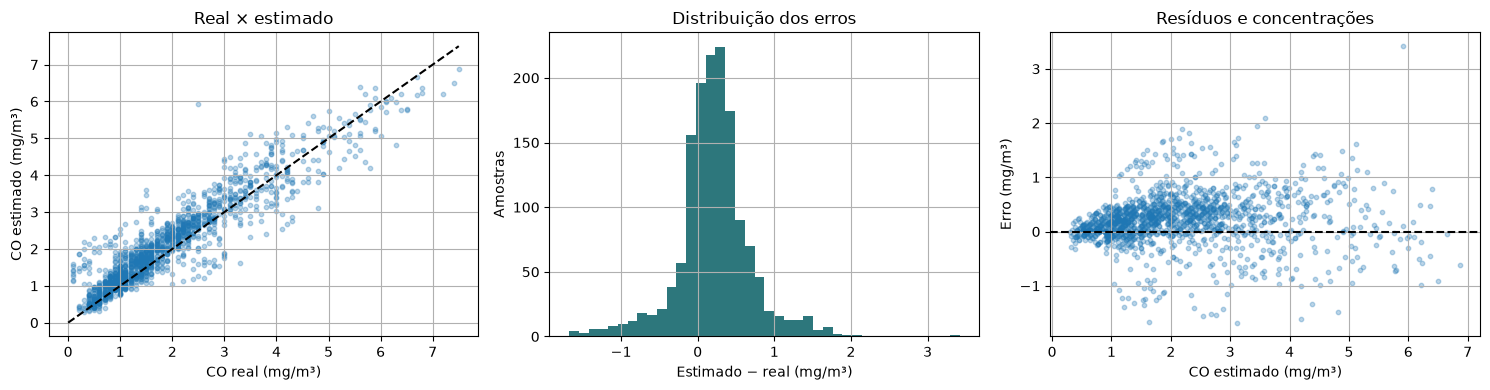

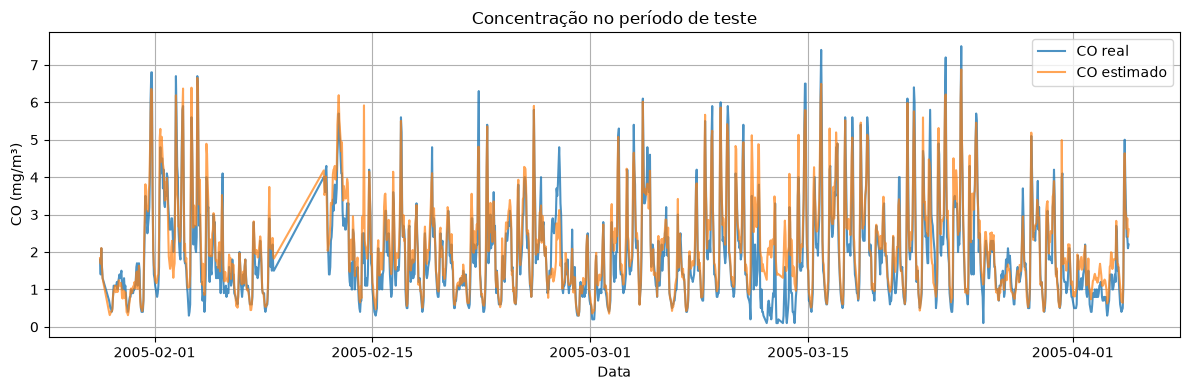

,grupo,n,MAE,RMSE,R2
0,CO até P80 do treino,1210,0.359845,0.501707,0.502192
1,CO acima de P80 do treino,259,0.500624,0.633186,0.592304


No teste: **MAE 0.385 mg/m³**, **RMSE 0.527 mg/m³**, **R² 0.836**. Variação de RMSE: **59.6%** de redução frente à média e **7.7%** frente à Ridge (valor negativo significa piora). O percentil 95 do erro absoluto foi **1.172 mg/m³**.

In [6]:
Xte = preprocessador.transform(teste[FEATURES])
yte = teste[ALVO].to_numpy()
constante = DummyRegressor(strategy="mean").fit(Xtr, ytr)
ridge = Ridge(alpha=1.0).fit(Xtr, ytr)
predicoes = {
    "Média do treino": np.maximum(0, constante.predict(Xte)),
    "Ridge linear": np.maximum(0, ridge.predict(Xte)),
    "MLP inicial": predizer(modelos["Inicial_16"], Xte),
    "MLP selecionada": predizer(melhor, Xte),
}
avaliacao = pd.DataFrame([{"modelo": nome, **metricas(yte, p)} for nome, p in predicoes.items()])
display(avaliacao)
avaliacao.to_csv(SAIDA / "metricas_teste.csv", index=False)
prev = predicoes["MLP selecionada"]
erros = prev - yte
resultado_teste = teste[["instante", ALVO]].copy()
resultado_teste["co_estimado_mg_m3"] = prev
resultado_teste["erro_mg_m3"] = erros
resultado_teste.to_csv(SAIDA / "predicoes_teste.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(yte, prev, alpha=.3, s=10)
limite = max(yte.max(), prev.max())
axes[0].plot([0, limite], [0, limite], "k--")
axes[0].set(xlabel="CO real (mg/m³)", ylabel="CO estimado (mg/m³)", title="Real × estimado")
axes[1].hist(erros, bins=40, color="#2d777c")
axes[1].set(xlabel="Estimado − real (mg/m³)", ylabel="Amostras", title="Distribuição dos erros")
axes[2].scatter(prev, erros, alpha=.3, s=10)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(xlabel="CO estimado (mg/m³)", ylabel="Erro (mg/m³)", title="Resíduos e concentrações")
fig.tight_layout(); fig.savefig(DOC / "figuras/avaliacao.png", dpi=140); plt.show()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(teste.instante, yte, label="CO real", alpha=.8)
ax.plot(teste.instante, prev, label="CO estimado", alpha=.7)
ax.set(title="Concentração no período de teste", ylabel="CO (mg/m³)", xlabel="Data")
ax.legend(); fig.tight_layout(); fig.savefig(DOC / "figuras/serie_teste.png", dpi=140); plt.show()
# Faixas definidas apenas por quantis do treino, sem significado sanitário.
q80 = float(np.quantile(ytr, .8))
grupos = pd.DataFrame([{"grupo": nome, "n": int(mask.sum()),
                        **metricas(yte[mask], prev[mask])}
                       for nome, mask in [("CO até P80 do treino", yte <= q80),
                                           ("CO acima de P80 do treino", yte > q80)] if mask.sum() > 1])
display(grupos)
grupos.to_csv(SAIDA / "erros_por_faixa.csv", index=False)
final = metricas(yte, prev)
ganho_media = 100 * (avaliacao.iloc[0].RMSE - final["RMSE"]) / avaliacao.iloc[0].RMSE
ganho_ridge = 100 * (avaliacao.iloc[1].RMSE - final["RMSE"]) / avaliacao.iloc[1].RMSE
display(Markdown(f"No teste: **MAE {final['MAE']:.3f} mg/m³**, **RMSE {final['RMSE']:.3f} mg/m³**, "
                 f"**R² {final['R2']:.3f}**. Variação de RMSE: **{ganho_media:.1f}%** de redução "
                 f"frente à média e **{ganho_ridge:.1f}%** frente à Ridge (valor negativo significa piora). "
                 f"O percentil 95 do erro absoluto foi **{np.quantile(abs(erros), .95):.3f} mg/m³**."))

### Interpretação, limitações e adequação

As métricas acima sustentam uma demonstração acadêmica de calibração ambiental.
Superar a média é necessário, mas a Ridge mostra se a complexidade da rede traz
ganho frente a um método linear. Se a RNA perder para a Ridge, isso deve orientar
a escolha futura de implantação; não alteramos a seleção depois de olhar o teste.

Verifique o erro nas concentrações altas: uma boa média global pode esconder
subestimação dos maiores valores. A distância entre erros de treino, validação e teste
evidencia dificuldade de generalização, mas mistura efeitos de sobreajuste e deriva.
Não eliminamos outliers de concentração: podem ser eventos ambientais relevantes.

Limitações: uma cidade e dispositivo, dados históricos, ausências e deriva,
uma semente e uma divisão temporal, sem intervalos de incerteza nem validação local.
Não foi definido um erro máximo aceitável por responsáveis operacionais; portanto,
não há evidência suficiente para declarar adequação a alertas públicos ou decisões
de segurança. Próximos passos: validação temporal em múltiplas janelas, múltiplas
sementes, avaliação local e calibração periódica. Uma RNN só seria comparável após
definir uma tarefa temporal e impedir vazamento na construção das janelas.

## 8. Demonstração funcional e integração simulada

Salvamos a rede, o pré-processador e a escala do alvo em um único pacote. A função
`estimar_co` representa o contrato de um futuro módulo de inferência: recebe medições
dos oito campos, trata ausências e retorna CO estimado em mg/m³ e a contagem de campos
ausentes. Não recebe o CO de referência. Abaixo, entradas e saídas vêm de cinco amostras
espaçadas do teste, que nunca foram usadas no ajuste nem na seleção.

O backend existente não recebe os cinco sensores químicos e não consome este modelo.
Uma integração futura precisaria de estação compatível em superfície, médias horárias,
validação das unidades/faixas, endpoint próprio e associação espacial ao painel de bueiros.
O CO estimado seria informação ambiental complementar, sem substituir as regras de
nível/obstrução e sem uso para autorizar entrada em bueiros.

In [7]:
pacote = dict(rede=melhor, preprocessador=preprocessador, escala_alvo=escala_alvo,
              features=FEATURES, unidade="mg/m³", alvo=ALVO, versoes=VERSOES,
              modelo=NOME_MELHOR, semente=SEED, tarefa="estimativa_contemporanea_CO")
joblib.dump(pacote, SAIDA / "modelo_co.joblib")
sys.path.insert(0, str(RAIZ_IA / "rede_neural"))
from inferencia import estimar_co
indices_demo = np.linspace(0, len(teste)-1, 5, dtype=int)
amostras = teste.iloc[indices_demo]
entradas = amostras[FEATURES].to_dict(orient="records")
resposta = estimar_co(entradas)
display(Markdown("**Entradas inéditas no treinamento (bloco de teste):**"))
display(amostras[["instante", *FEATURES]].reset_index(drop=True))
demo = pd.concat([amostras[["instante", ALVO]].reset_index(drop=True), resposta], axis=1)
display(Markdown("**Saídas da função de inferência e referência para conferência:**"))
display(demo)
assert np.allclose(resposta.co_estimado_mg_m3, prev[indices_demo])
demo.to_csv(SAIDA / "demonstracao.csv", index=False)
# Verifica o comportamento de falha sem fabricar uma estimativa para ausência total.
try:
    estimar_co([{campo: None for campo in FEATURES}])
except ValueError as erro:
    print("Ausência total corretamente recusada:", erro)
else:
    raise AssertionError("Uma leitura sem medições deveria ser recusada.")
print("Pacote salvo e recarregado; inferência consistente com a avaliação.")

**Entradas inéditas no treinamento (bloco de teste):**

,instante,PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2005-01-28 12:00:00,970.0,798.0,842.0,941.0,874.0,4.5,49.6,0.4210
1,2005-02-16 14:00:00,987.0,810.0,801.0,939.0,830.0,8.5,36.3,0.4026
2,2005-03-04 02:00:00,1089.0,750.0,765.0,1108.0,1117.0,3.9,80.9,0.6613
3,2005-03-20 01:00:00,1150.0,807.0,669.0,1243.0,1042.0,13.6,63.5,0.9857
4,2005-04-04 14:00:00,1071.0,1047.0,654.0,1129.0,816.0,28.5,13.1,0.5028


**Saídas da função de inferência e referência para conferência:**

,instante,CO(GT),co_estimado_mg_m3,campos_ausentes,tipo
0,2005-01-28 12:00:00,1.8,1.835755,0,simulacao_academica
1,2005-02-16 14:00:00,1.5,1.903949,0,simulacao_academica
2,2005-03-04 02:00:00,1.7,1.628500,0,simulacao_academica
3,2005-03-20 01:00:00,1.9,1.684758,0,simulacao_academica
4,2005-04-04 14:00:00,2.2,2.604709,0,simulacao_academica


Ausência total corretamente recusada: Cada leitura precisa de ao menos uma medição válida.
Pacote salvo e recarregado; inferência consistente com a avaliação.


### Uso real, acessibilidade e sustentabilidade

Um painel deve mostrar valor numérico, unidade, data da medição, indicação de estimativa
e indisponibilidade dos sensores; cores precisam vir acompanhadas de texto. Não há
dados pessoais no CSV utilizado. Uma implantação exigirá autenticação, proteção de
localizações sensíveis, controle de acesso e retenção mínima. A MLP pequena permite
inferência em CPU e uso de médias horárias, mas não medimos consumo energético nem
comprovamos ganho ambiental. Monitorar deriva e falhas será parte da manutenção.

O roteiro do vídeo, as instruções de execução e o relatório estão em `IA/documentacao`.
O vídeo depende do grupo e deve ser gravado antes da entrega.

In [8]:
resumo = {
    "python": platform.python_version(), "versoes": VERSOES,
    "dataset_sha256": hashlib.sha256(CSV.read_bytes()).hexdigest(),
    "registros_csv": len(bruto), "registros_datados": len(dados), "registros_utilizados": len(base),
    "sem_alvo": int(sem_alvo.sum()), "sem_entradas": int(sem_entradas.sum()),
    "periodo": [str(dados.instante.min()), str(dados.instante.max())],
    "divisao": resumo_divisao.to_dict(orient="records"),
    "features": FEATURES, "dimensoes": dimensoes, "parametros": parametros,
    "modelo_selecionado": NOME_MELHOR, "melhor_epoca": int(comparacao.iloc[0].melhor_epoca),
    "epocas_executadas": int(comparacao.iloc[0].epocas_executadas),
    "ganho_validacao_percentual": float(ganho_val),
    "metricas_teste": avaliacao.to_dict(orient="records"),
    "rmse_treino_selecionado": float(comparacao.iloc[0].RMSE_treino),
    "rmse_validacao_selecionado": float(comparacao.iloc[0].RMSE),
    "ganho_media_percentual": float(ganho_media), "ganho_ridge_percentual": float(ganho_ridge),
    "p95_erro_absoluto": float(np.quantile(abs(erros), .95)),
    "erro_medio_assinado": float(erros.mean()), "p80_treino": q80,
    "erros_por_faixa": grupos.to_dict(orient="records"),
}
(SAIDA / "resumo_execucao.json").write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8")
(SAIDA / "versoes_executadas.txt").write_text(
    "\n".join(f"{p}=={v}" for p, v in VERSOES.items()) + "\n", encoding="utf-8")
print("Evidências exportadas para", SAIDA.name, "e documentacao/figuras.")

Evidências exportadas para artefatos e documentacao/figuras.
